# Chapter 8 — Dyna-Q: 실제 경험과 모델 기반 Planning

Sutton & Barto 2판 §8.2의 Dyna-Q를 기존 ModularRL 컴포넌트로 조합한다.
환경은 앞 장과 같은 DLFS4 3×4 Gymnasium Gridworld다. 기존 04–06 Notebook은 그대로 유지한다.

[교재 Chapter 8](https://www.andrew.cmu.edu/course/10-703/textbook/BartoSutton.pdf) ·
[실행 예제](../../examples/gridworld_dyna_q.py) · [구조 평가](../../docs/ARCHITECTURE.md)

새 Learner 없이 실경험과 가상 전이가 **같은 Q Model**을 갱신할 수 있는지 확인한다.
이 Notebook은 교육용 기본 Dyna-Q와 Real n-step / Planning 1-step의 조합 검증이며,
Advanced Dyna-Q나 Dyna-DQN의 완성 구현은 아니다.

## 1. 기존 컴포넌트와 예제 함수

`Model`은 Q 추정·행동 선택, `TabularWorldModel`은 환경 결과 예측을 담당한다.
학습식은 Notebook에 다시 구현하지 않는다. 설치된 `modular_rl`과 저장소 예제만 사용한다.
예제 폴더는 설치 패키지가 아니므로 이 Notebook 위치에서 명시적으로 연결한다.

In [1]:
%matplotlib inline
import copy
import sys
import types
from importlib.machinery import ModuleSpec
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

example_dir = Path('../../examples').resolve()
if not (example_dir / 'gridworld_dyna_q.py').is_file():
    raise RuntimeError('Run this notebook from notebooks/dlfs4')
examples_package = types.ModuleType('examples')
examples_package.__path__ = [str(example_dir)]
examples_package.__spec__ = ModuleSpec('examples', loader=None, is_package=True)
examples_package.__spec__.submodule_search_locations = examples_package.__path__
sys.modules['examples'] = examples_package

from examples.gridworld_dyna_q import TabularWorldModel, plan, comparison
from modular_rl.component.action_selector import EpsilonGreedyActionSelector
from modular_rl.component.estimator import TabularQEstimator
from modular_rl.component.representation import IdentityRepresentation
from modular_rl.component.target_generator import TD0TargetGenerator
from modular_rl.component.update_rule import TabularQUpdateRule
from modular_rl.data import Transition
from modular_rl.environment import DLFS4_STATES, make_dlfs4_gridworld_env
from modular_rl.learner import TabularQLearner
from modular_rl.model import Model
from plotting import plot_grid

SEEDS, STEPS = (7, 11, 19), 1000
GAMMA, ALPHA, EPSILON = .9, .8, .1
torch.manual_seed(7)
plt.close('all')

## 2. Real Learning과 Planning의 수식

두 경로 모두 $Y=R+\gamma(1-\mathrm{terminated})\max_aQ(S',a)$와
$Q(S,A)\leftarrow Q(S,A)+\alpha(Y-Q(S,A))$를 사용한다.
차이는 경험의 출처다. Real은 `env.step`, Planning은 학습된 World Model의 예측이다.

실행 순서: **행동 → 환경 Step → Real Q 갱신 → World Model 관측 → Planning Q 갱신**.
Planning은 행동을 선택하거나 환경을 진행시키지 않는다. 모델이 관측한 쌍만 추출한다.

In [2]:
demo_model = Model(IdentityRepresentation(), TabularQEstimator(3, 2)).double()
demo_learner = TabularQLearner(demo_model, TD0TargetGenerator(.9), TabularQUpdateRule(.5))
demo_model.estimator.q_table[0, 1] = 2.
demo_model.estimator.q_table[2] = torch.tensor([4., 6.])
real = Transition(0, 1, 1., 2, False, False)
real_error = demo_learner.learn(real.to_batch())
assert np.isclose(real_error.item(), 4.4)
assert np.isclose(demo_model.estimator.q_table[0, 1].item(), 4.2)
world = TabularWorldModel()
world.observe(real)
planning_error = plan(world, demo_learner, steps=1, rng=np.random.default_rng(8))
assert np.isclose(planning_error.item(), 2.2)
assert np.isclose(demo_model.estimator.q_table[0, 1].item(), 5.3)
print('Target=6.4 | real delta=', real_error.item(), '| planning delta=', planning_error.item())
print('After real Q=4.2 | after planning Q=', demo_model.estimator.q_table[0, 1].item())

Target=6.4 | real delta= 4.4 | planning delta= 2.2
After real Q=4.2 | after planning Q= 5.300000000000001


## 3. World Model의 계약

관측한 `(state, action)`마다 최신 `(reward, next_state, terminated)`를 저장한다.
독립적인 NumPy Generator로 **관측한 쌍을 균등 추출**한다. 교재의 상태→관측 행동
계층적 추출과는 방문 가능한 행동 수가 다른 상태에서 분포가 다르다.

- 결정적 환경의 최신 결과 모델이다. 확률적 전이의 분포를 추정하지 않는다.
- ReplayBuffer의 과거 경험 무작위 재생과 달리 쌍별 최신 예측에서 가상 전이를 생성한다.
- Time-limit `truncated`는 환경 동역학에 넣지 않으며, 가상 전이는 `truncated=False`다.
- 자연 종료는 보존한다. Behavior log probability는 Planning 예측에 포함하지 않는다.
- 빈 모델의 `sample`은 오류이고 `plan`은 0회 갱신한다. 저장·반환 데이터는 복사한다.

## 4. 같은 실제 Environment Step 예산에서 비교

기존 장의 Episode 예산과 달리 각 run은 정확히 1,000번의 실제 Step을 수행한다.
기본 Q-learning / Dyna Planning=0,5,10과 Real n=3,5 + Planning=5를 비교한다.
γ=.9, α=.8, ε=.1이며 환경·행동·Planning RNG를 분리한다.
마지막 미완성 Episode는 외부 cutoff로 Bootstrap하고 완료 Episode 통계와 구분한다.
각 run의 Q와 환경은 독립적이며, Planning으로 Q가 바뀌면 이후 궤적도 달라질 수 있다.

In [3]:
results_7 = comparison(steps=STEPS, seeds=(7,))
print('seed 7:', [(r['n'], r['planning_steps'], r['steps'], r['planning_updates']) for r in results_7])

seed 7: [(1, 0, 1000, 0), (1, 0, 1000, 0), (1, 5, 1000, 5000), (1, 10, 1000, 10000), (3, 5, 1000, 5000), (5, 5, 1000, 5000)]


In [4]:
results_11 = comparison(steps=STEPS, seeds=(11,))
print('seed 11:', [(r['n'], r['planning_steps'], r['steps'], r['planning_updates']) for r in results_11])

seed 11: [(1, 0, 1000, 0), (1, 0, 1000, 0), (1, 5, 1000, 5000), (1, 10, 1000, 10000), (3, 5, 1000, 5000), (5, 5, 1000, 5000)]


In [5]:
results_19 = comparison(steps=STEPS, seeds=(19,))
print('seed 19:', [(r['n'], r['planning_steps'], r['steps'], r['planning_updates']) for r in results_19])

seed 19: [(1, 0, 1000, 0), (1, 0, 1000, 0), (1, 5, 1000, 5000), (1, 10, 1000, 10000), (3, 5, 1000, 5000), (5, 5, 1000, 5000)]


In [6]:
results = results_7 + results_11 + results_19
for seed in SEEDS:
    group = [r for r in results if r['seed'] == seed]
    baseline, zero = group[:2]
    assert baseline['trace'] == zero['trace']
    assert np.array_equal(baseline['q_values'], zero['q_values'])
    assert baseline['after'] == zero['after']
for r in results:
    assert r['steps'] == r['real_updates'] == STEPS
    assert r['planning_updates'] == STEPS * r['planning_steps']
    assert r['model_correct_pairs'] == r['world_pairs']
    print(f"seed={r['seed']} baseline={r['baseline']} real_n={r['n']} plan={r['planning_steps']} "
          f"env={r['steps']} real={r['real_updates']} model={r['model_updates']} "
          f"planning={r['planning_updates']} flush={r['flush_updates']} "
          f"episodes={r['episodes']} pairs={r['world_pairs']} "
          f"greedy_goal={r['after']['terminated']} greedy_steps={r['after']['steps']} "
          f"DP_steps={r['dp_steps']} RMSE={r['max_q_rmse']:.6f}")
print('Planning=0: action/target/error/reward/length/Q are exactly equal to baseline.')

seed=7 baseline=True real_n=1 plan=0 env=1000 real=1000 model=0 planning=0 flush=0 episodes=151 pairs=0 greedy_goal=True greedy_steps=5 DP_steps=5 RMSE=0.348640
seed=7 baseline=False real_n=1 plan=0 env=1000 real=1000 model=1000 planning=0 flush=0 episodes=151 pairs=38 greedy_goal=True greedy_steps=5 DP_steps=5 RMSE=0.348640
seed=7 baseline=False real_n=1 plan=5 env=1000 real=1000 model=1000 planning=5000 flush=0 episodes=168 pairs=38 greedy_goal=True greedy_steps=5 DP_steps=5 RMSE=0.000000
seed=7 baseline=False real_n=1 plan=10 env=1000 real=1000 model=1000 planning=10000 flush=0 episodes=169 pairs=38 greedy_goal=True greedy_steps=5 DP_steps=5 RMSE=0.000000
seed=7 baseline=False real_n=3 plan=5 env=1000 real=1000 model=1000 planning=5000 flush=269 episodes=134 pairs=32 greedy_goal=True greedy_steps=5 DP_steps=5 RMSE=0.176570
seed=7 baseline=False real_n=5 plan=5 env=1000 real=1000 model=1000 planning=5000 flush=579 episodes=144 pairs=37 greedy_goal=True greedy_steps=5 DP_steps=5 RMSE=

## 5. 실제 환경 Step과 추가 계산을 구분

같은 실제 환경 예산에도 Planning만큼 계산량이 늘어난다. 가로축은 실제 환경 Step, 보상은 탐색 중 Episode 보상이다.
Greedy 평가는 학습 후 별도 환경에서 한다. 성능 순위나 단일 Seed의 최적화 성공을 보장하지 않는다.

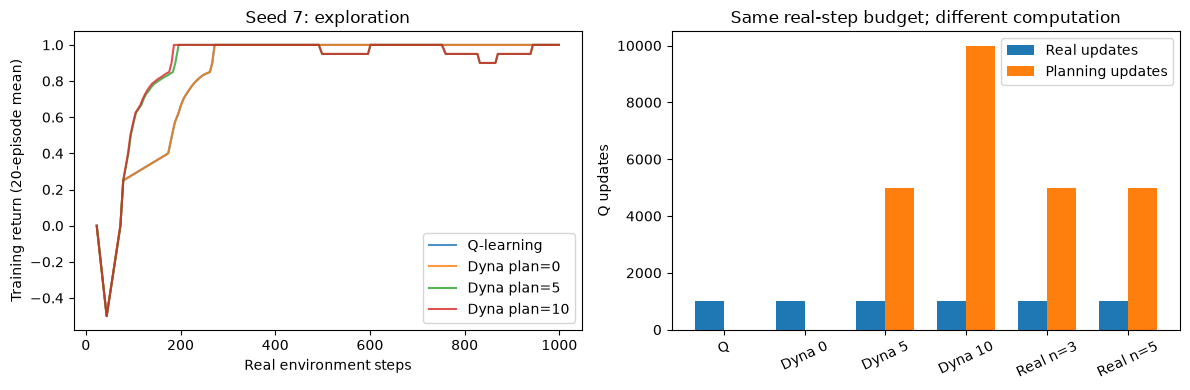

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for r in results_7[:4]:
    label = 'Q-learning' if r['baseline'] else f"Dyna plan={r['planning_steps']}"
    x = np.cumsum(r['episode_lengths'])
    y = r['training_rewards']
    rolling = np.array([np.mean(y[max(0, i-19):i+1]) for i in range(len(y))])
    axes[0].plot(x, rolling, label=label, alpha=.8)
labels = ['Q', 'Dyna 0', 'Dyna 5', 'Dyna 10', 'Real n=3', 'Real n=5']
axes[1].bar(np.arange(6)-.18, [r['real_updates'] for r in results_7], .36, label='Real updates')
axes[1].bar(np.arange(6)+.18, [r['planning_updates'] for r in results_7], .36, label='Planning updates')
axes[1].set_xticks(range(6), labels, rotation=25)
axes[0].set(xlabel='Real environment steps', ylabel='Training return (20-episode mean)', title='Seed 7: exploration')
axes[1].set(ylabel='Q updates', title='Same real-step budget; different computation')
for ax in axes: ax.legend()
fig.tight_layout()
plt.show()

## 6. Q-table, Greedy Policy와 DP 비교

표의 RMSE는 목표 상태를 제외한 10개 상태에서 `max Q`와 DP 최적 V를 비교한다.
정책 화살표는 최대 Q 동률을 모두 표시하지만 실제 deterministic 행동은 최소 인덱스다.
관측되지 않은 쌍의 World Model 정확성은 주장하지 않는다.

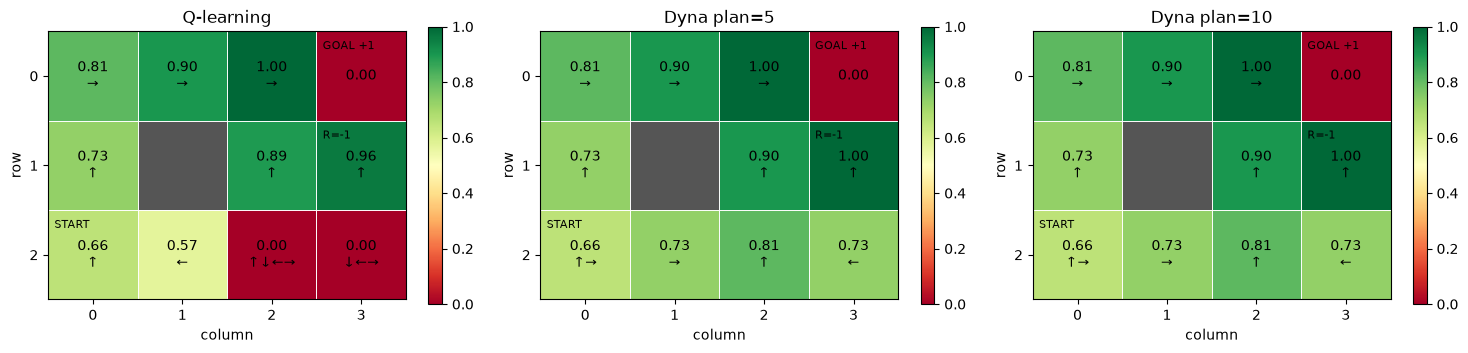

real_n=1 planning=0 baseline=True Q:
[[ 0.5733  0.6559  0.7232  0.81  ]
 [ 0.8087  0.81    0.7278  0.9   ]
 [ 0.72    0.7374  0.7776  1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.729   0.5905  0.6551  0.655 ]
 [ 0.8916  0.      0.     -0.224 ]
 [ 0.96    0.      0.     -0.224 ]
 [ 0.6561  0.5895  0.5905  0.3401]
 [ 0.      0.      0.5669  0.    ]
 [ 0.      0.      0.      0.    ]
 [-0.8     0.      0.      0.    ]]
Greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
real_n=1 planning=0 baseline=False Q:
[[ 0.5733  0.6559  0.7232  0.81  ]
 [ 0.8087  0.81    0.7278  0.9   ]
 [ 0.72    0.7374  0.7776  1.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.729   0.5905  0.6551  0.655 ]
 [ 0.8916  0.      0.     -0.224 ]
 [ 0.96    0.      0.     -0.224 ]
 [ 0.6561  0.5895  0.5905  0.3401]
 [ 0.      0.      0.5669  0.    ]
 [ 0.      0.      0.      0.    ]
 [-0.8     0.      0.      0.    ]]
Greedy path: [(2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3)]
real_n=1 planning=5 baseline=

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, r in zip(axes, [results_7[0], results_7[2], results_7[3]]):
    q = r['q_values']
    policy = (q == q.max(-1, keepdims=True)).astype(float)
    policy /= policy.sum(-1, keepdims=True)
    title = 'Q-learning' if r['baseline'] else f"Dyna plan={r['planning_steps']}"
    plot_grid(q.max(-1), policy, title=title, ax=ax)
fig.tight_layout()
plt.show()
for r in results_7:
    print(f"real_n={r['n']} planning={r['planning_steps']} baseline={r['baseline']} Q:")
    print(np.round(r['q_values'], 4))
    print('Greedy path:', [DLFS4_STATES[s] for s in r['after']['path']])
for index, label in enumerate(labels):
    errors = np.array([results_7[index]['max_q_rmse'], results_11[index]['max_q_rmse'], results_19[index]['max_q_rmse']])
    print(f"{label}: seed RMSE={np.round(errors, 6)} mean={errors.mean():.6f} std={errors.std():.6f}")

## 7. Real n-step과 Planning 1-step

Real Target은 $G=\sum_{k=0}^{m-1}\gamma^kR_{t+k+1}+\gamma^m\max_aQ(S_{t+m},a)$다.
자연 종료에서는 마지막 Bootstrap을 제외한다. 기존 TD0를 역순 합성하고 Window의 가장 오래된 행만 갱신한다.
n=1은 기존 QLearner에 직접 위임한다. Planning은 n에 관계없이 항상 1-step이다.

Real n=3의 처음 2 Step에는 Real 갱신이 없지만 World Model 관측과 Planning은 진행한다.
경계 Step의 Planning 후 잔여 Window를 Flush한다. Flush는 추가 step·act·observe·plan을 하지 않으며,
각 호출은 이전 Planning/Real 갱신을 반영한 Q에서 Target을 고정한다.
모든 실제 Transition은 정확히 한 번 Real 갱신의 시작점이 된다. 가상 경험은 Real Window에 넣지 않는다.

n= 1 | first five (real, planning, flush): [(1, 5, 0), (1, 5, 0), (1, 5, 0), (1, 5, 0), (1, 5, 0)]
end flush= 0 | partial episode= {'steps': 1, 'reward': 0.0}
n= 3 | first five (real, planning, flush): [(0, 5, 0), (0, 5, 0), (1, 5, 0), (1, 5, 0), (1, 5, 0)]
end flush= 269 | partial episode= {'steps': 1, 'reward': 0.0}
n= 5 | first five (real, planning, flush): [(0, 5, 0), (0, 5, 0), (0, 5, 0), (0, 5, 0), (1, 5, 0)]
end flush= 579 | partial episode= {'steps': 3, 'reward': 0.0}


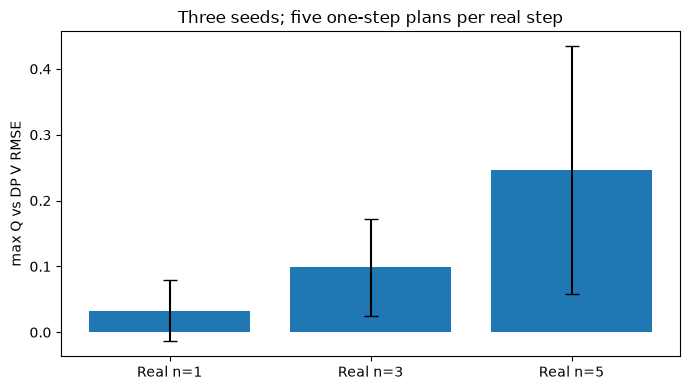

In [9]:
for r in results_7[2:3] + results_7[4:]:
    first_rows = r['trace'][:5]
    print('n=', r['n'], '| first five (real, planning, flush):',
          [(row['real_updates'], row['planning_updates'], row['flush_updates']) for row in first_rows])
    print('end flush=', r['flush_updates'], '| partial episode=', r['partial_episode'])
assert all(row['real_updates'] == 0 for row in results_7[4]['trace'][:2])
assert all(row['planning_updates'] == 5 for row in results_7[4]['trace'][:2])
fig, ax = plt.subplots(figsize=(7, 4))
means = [np.mean([results_7[i]['max_q_rmse'], results_11[i]['max_q_rmse'], results_19[i]['max_q_rmse']]) for i in (2,4,5)]
stds = [np.std([results_7[i]['max_q_rmse'], results_11[i]['max_q_rmse'], results_19[i]['max_q_rmse']]) for i in (2,4,5)]
ax.bar(['Real n=1', 'Real n=3', 'Real n=5'], means, yerr=stds, capsize=5)
ax.set(ylabel='max Q vs DP V RMSE', title='Three seeds; five one-step plans per real step')
fig.tight_layout()
plt.show()

## 8. Offline Pretraining, Online Adaptation와 Idle Planning

`observe`만으로 World Model을 사전학습해도 Q는 변하지 않는다. 같은 쌍을 다시 관측하면
최신 결과로 대체한다. 확률적 모델·Drift Detection은 구현하지 않는다.
`plan(world, learner, steps=..., rng=...)`은 환경을 받지 않아 실제 제어 주기 사이에도 호출할 수 있다.
시간 기반 Scheduler는 추가하지 않았다.

In [10]:
idle_model = Model(IdentityRepresentation(), TabularQEstimator(3, 2)).double()
idle_learner = TabularQLearner(idle_model, TD0TargetGenerator(.9), TabularQUpdateRule(.5))
pretrained = TabularWorldModel()
q_before = idle_model.estimator.q_table.clone()
for transition in [Transition(0, 1, 1., 2, False, True)]:
    pretrained.observe(transition)
assert torch.equal(q_before, idle_model.estimator.q_table)
idle_env = make_dlfs4_gridworld_env(max_episode_steps=20)
try:
    idle_env.reset(seed=7)
    env_before = (idle_env.unwrapped._state, idle_env._elapsed_steps, copy.deepcopy(idle_env.unwrapped.np_random.bit_generator.state))
    behavior_before = torch.get_rng_state().clone()
    planning_rng = np.random.default_rng(8)
    errors1 = plan(pretrained, idle_learner, steps=5, rng=planning_rng)
    errors2 = plan(pretrained, idle_learner, steps=10, rng=planning_rng)
    assert env_before == (idle_env.unwrapped._state, idle_env._elapsed_steps, idle_env.unwrapped.np_random.bit_generator.state)
    assert torch.equal(behavior_before, torch.get_rng_state())
    assert len(pretrained) == 1
    print('Offline observe: Q unchanged | idle real steps=0 | planning updates=', errors1.numel()+errors2.numel())
    print('Idle Q(0,1)=', idle_model.estimator.q_table[0,1].item())
finally:
    idle_env.close()

Offline observe: Q unchanged | idle real steps=0 | planning updates= 15
Idle Q(0,1)= 0.999969482421875


## 9. Checkpoint와 컴포넌트 재사용 평가

- Q는 `Model.state_dict()`, 환경 예측은 `world.state_dict()`로 따로 저장한다.
- Planning Generator 상태, Torch 행동 RNG(필요 시 CUDA RNG), γ/α/ε/n/예산도 저장한다.
- n-step 중간 재개에는 시간순 Pending Window가 필요하다. 일반 환경의 중간 Episode 재개는
  환경 위치·RNG·TimeLimit 경과 Step까지 별도로 복원해야 한다. 편의 `run_steps`는 live checkpoint API가 아니다.
- 두 경로가 같은 Model을 가진 별도 QLearner를 사용하면 γ/α 등 Target 설정도 독립적으로 지정할 수 있다.
- ReplayBuffer는 데이터셋 저장에는 사용 가능하지만 쌍별 예측·모델 적응·Planning Sampler를 대신하지 않는다.

현재 구조만으로 Real/Planning 분리와 유휴 Planning이 가능했다. 기존 QLearner는1-step max Target이
고정돼 있으므로 Real n-step 조합과 스케줄은 예제 함수가 담당한다. 이번에는 공통 프레임워크로 올리지 않았다.

향후 Prioritized Planning에는 쌍별 Priority/TD Error·Predecessor가, All-action에는 상태별 행동 후보가,
모델 신뢰도 기반 Q(σ)에는 다단계 예측·Target/Behavior 확률·선택 시점 σ/신뢰도 기록이 필요하다.
Dyna-DQN은 World Model을 Neural/GPR 등으로 바꾸는 것 외에도 Target Network·Optimizer·실제/가상 Batch
관리·모델 오차와 분포 변화가 필요하다. 관수·온도 제어의 연속 상태·지연 동역학은 이번 Tabular 모델이 표현하지 못한다.

공통화 후보는 owned ordered window, eligible-head/flush 스케줄, frozen Q snapshot,
Return→UpdateRule 연결, sampling-time metadata, World Model 예측과 Planning 검색제어다.
알고리즘별 endpoint와 갱신 순서 차이를 확인한 뒤 별도 설계할 항목이며 이번 단계에서 추상 계층을 추가하지 않았다.